# Lab 2 — Ciclo de treino, vazamento e métricas
**Individual · 1,0 ponto na AV1 · 08/10/2026 · horário da atividade no Classroom**

Leia `ENUNCIADO.pdf` antes de preencher. A base comum está incluída; não é necessário usar o banco do projeto.

O notebook executa a preparação e um teste pequeno de ambiente. Nas atividades avaliadas, complete os **TODO** e substitua as mensagens de pendência por resultados. Não há métricas pré-medidas para copiar.

Ordem: preparação → B2 → A → C → D7 → D4–D6 → avaliação final → relatório.

## 0. Ambiente e pasta
No Colab, extraia o ZIP conforme o enunciado e execute `%cd /content/classroom-lab-02` antes da próxima célula. Localmente, abra este notebook na pasta extraída. CPU é suficiente.

In [1]:
from pathlib import Path
import sys, copy, time, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset
from apoio import FEATURES, carregar_base, fixar_semente, criar_modelo
from apoio import treinar_epoca, avaliar_perda, obter_escores

SEED = 42
fixar_semente(SEED)
DISPOSITIVO = 'cpu'
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
for pacote in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'torch']:
    print(pacote, importlib.metadata.version(pacote))

Python: 3.14.4
numpy 2.5.4
pandas 3.0.6
scikit-learn 1.9.1
matplotlib 3.11.2
torch 2.14.1+cpu


### Leitura e conferência da base
`carregar_base` lê o CSV com `;`, confere sua integridade e cria o alvo e os identificadores de controle. As únicas entradas permitidas estão em `FEATURES`. Não aprende média, desvio, pesos ou partições.

Ver as contagens do arquivo não é treinar um modelo. Depois da B2, o teste principal deve permanecer fora das decisões e dos experimentos de erro.

In [2]:
base = carregar_base()
print(base.head().to_string(index=False))
print('\nLinhas:', len(base), '| características:', len(FEATURES))
print('Classe positiva:', int(base.alvo.sum()), '| proporção:', base.alvo.mean())
print('Perfis distintos:', base.grupo_perfil.nunique())
assert set(FEATURES).isdisjoint({'quality', 'alvo', 'id_linha', 'grupo_perfil'})

 fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol  quality  alvo  id_linha         grupo_perfil
           7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978 3.51       0.56      9.4        5     0         0 16231909345439519184
           7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968 3.20       0.68      9.8        5     0         1  8814798900776851426
           7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970 3.26       0.65      9.8        5     0         2 16179437306182617678
          11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980 3.16       0.58      9.8        6     0         3  8450966096714587765
           7.4      

### Exemplo mínimo: o que faz uma atualização
O bloco a seguir usa **quatro observações artificiais com duas entradas**, apenas para conferir instalação e formas. Não usa Wine Quality, não mede generalização e não atende às partes avaliadas. Um logit é transformado em escore por sigmoide só ao obter previsões; a perda recebe o logit.

In [3]:
x_exemplo = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_exemplo = torch.tensor([0., 0., 0., 1.])
exemplo_loader = DataLoader(TensorDataset(x_exemplo, y_exemplo), batch_size=2)
exemplo_modelo = criar_modelo(2).to(DISPOSITIVO)
exemplo_otimizador = torch.optim.Adam(exemplo_modelo.parameters(), lr=0.001)
exemplo_perda = treinar_epoca(exemplo_modelo, exemplo_loader, exemplo_otimizador,
                              nn.BCEWithLogitsLoss(), DISPOSITIVO)
print('Teste de ambiente concluído. Perda de treino artificial:', exemplo_perda)
del exemplo_modelo, exemplo_loader, exemplo_otimizador
fixar_semente(SEED)

Teste de ambiente concluído. Perda de treino artificial: 0.7283297777175903


## B2. Separe antes de normalizar
Implemente aproximadamente 60/20/20, conservando `grupo_perfil` em uma única partição. Use uma semente declarada. Consulte `GroupShuffleSplit`; proporções de grupos não garantem as mesmas proporções de linhas.

Retorne um dicionário com `treino`, `validacao`, `teste`, cada qual contendo um DataFrame. Mostre cobertura, interseção de linhas e perfis, contagens e classes. Não use IDs como características.

In [4]:
from sklearn.model_selection import GroupShuffleSplit

def particionar_sem_vazar(df, semente=42):
    """B2: 60/20/20 aproximado, perfis idênticos (grupo_perfil) sempre na mesma partição.

    1) reserva ~20% dos GRUPOS para teste; 2) divide o restante (80%) em treino/validação
    com test_size=0.25 (0,25 * 0,80 = 0,20 do total). Semente fixa, escolhida a priori.
    """
    gss_teste = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=semente)
    idx_dev, idx_te = next(gss_teste.split(df, groups=df['grupo_perfil']))
    dev, teste = df.iloc[idx_dev], df.iloc[idx_te]
    gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=semente)
    idx_tr, idx_va = next(gss_val.split(dev, groups=dev['grupo_perfil']))
    return {'treino': dev.iloc[idx_tr].reset_index(drop=True),
            'validacao': dev.iloc[idx_va].reset_index(drop=True),
            'teste': teste.reset_index(drop=True)}

particoes = particionar_sem_vazar(base, SEED)

# ---- auditoria ----
linhas = []
for nome, p in particoes.items():
    linhas.append({'conjunto': nome, 'linhas': len(p), '% linhas': 100*len(p)/len(base),
                   'positivos': int(p.alvo.sum()), 'negativos': int((p.alvo == 0).sum()),
                   'prop. positiva': p.alvo.mean(), 'perfis': p.grupo_perfil.nunique()})
tabela_b2 = pd.DataFrame(linhas)
print(tabela_b2.round(4).to_string(index=False))

ids = {n: set(p.id_linha) for n, p in particoes.items()}
perfis = {n: set(p.grupo_perfil) for n, p in particoes.items()}
pares = [('treino', 'validacao'), ('treino', 'teste'), ('validacao', 'teste')]
print('\nCobertura: união dos ids == todas as linhas?', set().union(*ids.values()) == set(base.id_linha),
      '| soma das linhas =', sum(len(p) for p in particoes.values()), 'de', len(base))
for a, b in pares:
    print(f'{a} x {b}: ids em comum = {len(ids[a] & ids[b])} | perfis em comum = {len(perfis[a] & perfis[b])}')
    assert not ids[a] & ids[b] and not perfis[a] & perfis[b]
assert set().union(*ids.values()) == set(base.id_linha)
assert all(p.alvo.nunique() == 2 for p in particoes.values())
print('Ambas as classes presentes nas três partições.')
print('Linhas duplicadas (mesmas 11 medidas) em toda a base:', int(base.duplicated(FEATURES).sum()))
tabela_b2.to_csv(RESULTADOS/'b2_particoes.csv', index=False)

 conjunto  linhas  % linhas  positivos  negativos  prop. positiva  perfis
   treino     961   60.1001        139        822          0.1446     815
validacao     318   19.8874         33        285          0.1038     272
    teste     320   20.0125         45        275          0.1406     272

Cobertura: união dos ids == todas as linhas? True | soma das linhas = 1599 de 1599
treino x validacao: ids em comum = 0 | perfis em comum = 0
treino x teste: ids em comum = 0 | perfis em comum = 0
validacao x teste: ids em comum = 0 | perfis em comum = 0
Ambas as classes presentes nas três partições.
Linhas duplicadas (mesmas 11 medidas) em toda a base: 240


### B1. Cinco cenários
Responda no README aos cinco cenários do enunciado: avaliações de produtos; turbinas; spam; radiografias; transações. Declare o uso e as hipóteses. Na quinta resposta, discuta tempo e identidade dos clientes. As respostas não precisam de bancos adicionais.

## A1. Dataset próprio
Implemente a classe abaixo com as estatísticas opcionais. Aprenda média/desvio somente no treino e passe-os aos outros conjuntos. Trate desvio zero, preserve o alinhamento e devolva `float32`: X `[11]`, y escalar. Mostre as verificações solicitadas.

In [5]:
class MeuDataset(Dataset):
    """Dataset tabular de UMA partição do Wine Quality (11 características -> alvo binário)."""

    def __init__(self, df, features, media=None, desvio=None):
        """Prepara tensores float32 já padronizados.

        - Se `media`/`desvio` não forem passados (treino), são aprendidos AQUI, só com as linhas de `df`.
          Convenção: desvio populacional (ddof=0), isto é, denominador N.
        - Se forem passados (validação/teste), são reutilizados sem recalcular.
        - Desvio zero é substituído por 1 para evitar divisão por zero.
        """
        X = df[list(features)].to_numpy(dtype=np.float64)
        if media is None:
            media = X.mean(axis=0)
        if desvio is None:
            desvio = X.std(axis=0, ddof=0)
        desvio = np.where(np.asarray(desvio) == 0, 1.0, desvio)
        self.media = np.asarray(media, dtype=np.float64)
        self.desvio = np.asarray(desvio, dtype=np.float64)
        self.X = torch.tensor((X - self.media) / self.desvio, dtype=torch.float32)
        self.y = torch.tensor(df['alvo'].to_numpy(), dtype=torch.float32)

    def __len__(self):
        """Número de observações da partição."""
        return len(self.y)

    def __getitem__(self, indice):
        """Devolve (X [11] float32, y escalar float32) da observação `indice`, alinhados."""
        return self.X[indice], self.y[indice]

ds_treino = MeuDataset(particoes['treino'], FEATURES)
ds_validacao = MeuDataset(particoes['validacao'], FEATURES, ds_treino.media, ds_treino.desvio)
ds_teste = MeuDataset(particoes['teste'], FEATURES, ds_treino.media, ds_treino.desvio)

print('Comprimentos:', len(ds_treino), len(ds_validacao), len(ds_teste))
x0, y0 = ds_treino[0]
print('Exemplo: X', tuple(x0.shape), x0.dtype, '| y', tuple(y0.shape), y0.dtype)
for nome, ds in [('treino', ds_treino), ('validação', ds_validacao), ('teste', ds_teste)]:
    print(f'{nome}: NaN/inf em X? {not bool(torch.isfinite(ds.X).all())} | y em {{0,1}}? {bool(((ds.y==0)|(ds.y==1)).all())}')
print('\nMédia por característica (treino, deve ser ~0):', ds_treino.X.mean(0).numpy().round(3))
print('Desvio por característica (treino, deve ser ~1):', ds_treino.X.std(0, unbiased=False).numpy().round(3))
print('Média da validação (NÃO precisa ser 0):', ds_validacao.X.mean(0).numpy().round(3))
print('Validação/teste usam as MESMAS estatísticas do treino?',
      np.array_equal(ds_validacao.media, ds_treino.media) and np.array_equal(ds_teste.desvio, ds_treino.desvio))
# conferência independente: validação padronizada à mão com média/desvio do treino
ref = (particoes['validacao'][FEATURES].to_numpy() - particoes['treino'][FEATURES].to_numpy().mean(0)) \
      / particoes['treino'][FEATURES].to_numpy().std(0, ddof=0)
print('Máx. diferença p/ padronização manual com estatísticas do treino:', float(np.abs(ref - ds_validacao.X.numpy()).max()))
lote_x, lote_y = next(iter(DataLoader(ds_treino, batch_size=64)))
print('Lote: X', tuple(lote_x.shape), lote_x.dtype, '| y', tuple(lote_y.shape), lote_y.dtype)

Comprimentos: 961 318 320
Exemplo: X (11,) torch.float32 | y () torch.float32
treino: NaN/inf em X? False | y em {0,1}? True
validação: NaN/inf em X? False | y em {0,1}? True
teste: NaN/inf em X? False | y em {0,1}? True

Média por característica (treino, deve ser ~0): [ 0.  0. -0. -0.  0.  0.  0.  0.  0. -0.  0.]
Desvio por característica (treino, deve ser ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Média da validação (NÃO precisa ser 0): [ 0.091  0.134  0.017 -0.009  0.011  0.104  0.033  0.133  0.005 -0.079
 -0.06 ]
Validação/teste usam as MESMAS estatísticas do treino? True
Máx. diferença p/ padronização manual com estatísticas do treino: 4.6906653139444643e-07
Lote: X (64, 11) torch.float32 | y (64,) torch.float32


## A2. Três DataLoaders
Preencha a tabela de parâmetros no README e crie os carregadores. Na avaliação não descarte observações. `obter_escores` devolve rótulos e escores percorridos juntos, evitando confundir uma ordem de rótulos com outra de previsões.

In [6]:
# Escolhas (justificativas completas no README):
#  treino    : batch 64, shuffle=True,  drop_last=False, num_workers=0
#  validacao : batch 256, shuffle=False, drop_last=False, num_workers=0
#  teste     : batch 256, shuffle=False, drop_last=False, num_workers=0
g_treino = torch.Generator().manual_seed(SEED)
loader_treino = DataLoader(ds_treino, batch_size=64, shuffle=True, drop_last=False,
                           num_workers=0, generator=g_treino)
loader_validacao = DataLoader(ds_validacao, batch_size=256, shuffle=False, drop_last=False, num_workers=0)
loader_teste = DataLoader(ds_teste, batch_size=256, shuffle=False, drop_last=False, num_workers=0)

tabela_a2 = pd.DataFrame([
    {'conjunto': n, 'batch_size': l.batch_size, 'shuffle': s, 'drop_last': l.drop_last,
     'num_workers': l.num_workers, 'n_obs': len(l.dataset), 'n_lotes': len(l)}
    for n, l, s in [('treino', loader_treino, True), ('validacao', loader_validacao, False),
                    ('teste', loader_teste, False)]])
print(tabela_a2.to_string(index=False))
# a ordem dos escores deve acompanhar a dos rótulos: confere com a ordem do DataFrame
r, _ = obter_escores(criar_modelo(11), loader_validacao, DISPOSITIVO)
print('Rótulos percorridos == alvo da partição (mesma ordem)?', np.array_equal(r, particoes['validacao'].alvo.to_numpy()))
tabela_a2.to_csv(RESULTADOS/'a2_loaders.csv', index=False)

 conjunto  batch_size  shuffle  drop_last  num_workers  n_obs  n_lotes
   treino          64     True      False            0    961       16
validacao         256    False      False            0    318        2
    teste         256    False      False            0    320        2
Rótulos percorridos == alvo da partição (mesma ordem)? True


## A3. Tempo de uma época
Teste os quatro lotes com a rede de apoio **sem BatchNorm**. Controle o estado inicial, novo otimizador, dados e dispositivo; faça aquecimento antes de medir. Percorra o treino inteiro. Use `treinar_epoca`, `time.perf_counter` e, se necessário, sincronização CUDA. Registre repetições e mediana; explique o resultado, inclusive se não for monotônico.

repeticao        1       2       3
batch_size                        
1           0.8188  0.9185  1.2832
8           0.2707  0.1303  0.1047
64          0.0170  0.0199  0.0173
512         0.0067  0.0066  0.0074

 batch_size  mediana_s  min_s  max_s  passos  exemplos  ms_por_passo  speedup_vs_lote1
          1     0.9185 0.8188 1.2832     961       961        0.9558            1.0000
          8     0.1303 0.1047 0.2707     121       961        1.0769            7.0490
         64     0.0173 0.0170 0.0199      16       961        1.0838           52.9714
        512     0.0067 0.0066 0.0074       2       961        3.3253          138.1117
Equipamento: Intel64 Family 6 Model 158 Stepping 12, GenuineIntel | Windows 11 | torch 2.14.1+cpu | CPU, 6 threads


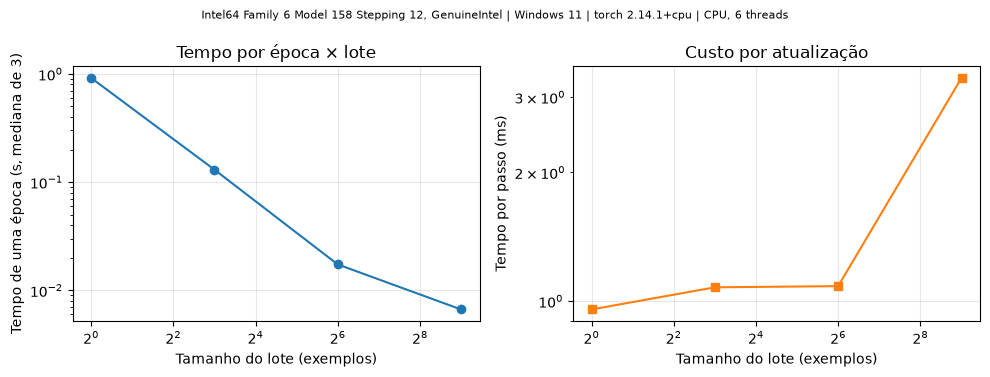

In [7]:
import platform
tamanhos_lote = [1, 8, 64, 512]
tempos = []
fixar_semente(SEED)
modelo_a3 = criar_modelo(11, batchnorm=False).to(DISPOSITIVO)   # SEM BatchNorm
estado_inicial_a3 = copy.deepcopy(modelo_a3.state_dict())
criterio_a3 = nn.BCEWithLogitsLoss()

def uma_epoca_medida(bs, seed_loader):
    modelo_a3.load_state_dict(estado_inicial_a3)                 # mesmo estado inicial
    otim = torch.optim.Adam(modelo_a3.parameters(), lr=1e-3)    # otimizador novo
    ld = DataLoader(ds_treino, batch_size=bs, shuffle=True, drop_last=False, num_workers=0,
                    generator=torch.Generator().manual_seed(seed_loader))
    t0 = time.perf_counter()
    treinar_epoca(modelo_a3, ld, otim, criterio_a3, DISPOSITIVO)  # CPU: sem sincronização necessária
    return time.perf_counter() - t0, len(ld)

for bs in tamanhos_lote:
    uma_epoca_medida(bs, SEED)                                   # aquecimento (fora da medição)
    for rep in range(1, 4):
        seg, passos = uma_epoca_medida(bs, SEED + rep)
        tempos.append({'batch_size': bs, 'repeticao': rep, 'segundos': seg, 'passos': passos,
                       'exemplos': len(ds_treino)})
df_tempos = pd.DataFrame(tempos)
resumo_a3 = df_tempos.groupby('batch_size').agg(
    mediana_s=('segundos', 'median'), min_s=('segundos', 'min'), max_s=('segundos', 'max'),
    passos=('passos', 'first'), exemplos=('exemplos', 'first')).reset_index()
resumo_a3['ms_por_passo'] = 1000 * resumo_a3.mediana_s / resumo_a3.passos
resumo_a3['speedup_vs_lote1'] = resumo_a3.mediana_s.iloc[0] / resumo_a3.mediana_s
print(df_tempos.pivot(index='batch_size', columns='repeticao', values='segundos').round(4).to_string())
print()
print(resumo_a3.round(4).to_string(index=False))
equip = f"{platform.processor()} | {platform.system()} {platform.release()} | torch {torch.__version__} | CPU, {torch.get_num_threads()} threads"
print('Equipamento:', equip)
df_tempos.to_csv(RESULTADOS/'a3_tempos_brutos.csv', index=False)
resumo_a3.to_csv(RESULTADOS/'a3_tempos_resumo.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(resumo_a3.batch_size, resumo_a3.mediana_s, 'o-')
ax[0].set_xscale('log', base=2); ax[0].set_yscale('log')
ax[0].set_xlabel('Tamanho do lote (exemplos)'); ax[0].set_ylabel('Tempo de uma época (s, mediana de 3)')
ax[0].set_title('Tempo por época × lote'); ax[0].grid(alpha=.3)
ax[1].plot(resumo_a3.batch_size, resumo_a3.ms_por_passo, 's-', color='C1')
ax[1].set_xscale('log', base=2); ax[1].set_yscale('log')
ax[1].set_xlabel('Tamanho do lote (exemplos)'); ax[1].set_ylabel('Tempo por passo (ms)')
ax[1].set_title('Custo por atualização'); ax[1].grid(alpha=.3)
fig.suptitle(equip, fontsize=8); fig.tight_layout()
fig.savefig(RESULTADOS/'a3_tempo_por_lote.png', dpi=130); plt.show()

## A4. BatchNorm com último lote 1
Use um subconjunto de 65 observações do treino e lote 64, ou outra condição equivalente. Confirme o resto. Use `criar_modelo(11, batchnorm=True)`, modo de treino e `drop_last=False`. Capture especificamente o erro esperado, mostre sua mensagem e depois execute a correção que escolheu. Preserve as outras partes do notebook.

In [8]:
fixar_semente(SEED)
N_SUB, LOTE = 65, 64
rng = np.random.default_rng(SEED)
idx_sub = rng.choice(len(ds_treino), size=N_SUB, replace=False)        # apenas do TREINO
sub = Subset(ds_treino, idx_sub.tolist())
print(f'Subconjunto: {len(sub)} obs | lote {LOTE} | resto = {len(sub) % LOTE}  (último lote terá {len(sub) % LOTE} exemplo)')
assert len(sub) % LOTE == 1

mod_bn = criar_modelo(11, batchnorm=True).to(DISPOSITIVO)
otim_bn = torch.optim.Adam(mod_bn.parameters(), lr=1e-3)
loader_falha = DataLoader(sub, batch_size=LOTE, shuffle=False, drop_last=False, num_workers=0)
try:
    treinar_epoca(mod_bn, loader_falha, otim_bn, nn.BCEWithLogitsLoss(), DISPOSITIVO)
    print('Sem erro (inesperado).')
except ValueError as e:                  # captura específica: erro de BatchNorm com 1 valor por canal
    print('ERRO CAPTURADO (drop_last=False):', type(e).__name__, '-', e)

# Correção: descartar o último lote incompleto SOMENTE no treino (drop_last=True)
mod_bn = criar_modelo(11, batchnorm=True).to(DISPOSITIVO)
otim_bn = torch.optim.Adam(mod_bn.parameters(), lr=1e-3)
loader_ok = DataLoader(sub, batch_size=LOTE, shuffle=True, drop_last=True, num_workers=0,
                       generator=torch.Generator().manual_seed(SEED))
perda = treinar_epoca(mod_bn, loader_ok, otim_bn, nn.BCEWithLogitsLoss(), DISPOSITIVO)
print(f'Correção drop_last=True: {len(loader_ok)} lote(s) de {LOTE}, perda da época = {perda:.4f}; '
      f'{N_SUB - len(loader_ok)*LOTE} observação descartada por época (sorteada de novo com shuffle=True).')

Subconjunto: 65 obs | lote 64 | resto = 1  (último lote terá 1 exemplo)
ERRO CAPTURADO (drop_last=False): ValueError - Expected more than 1 value per channel when training, got input size torch.Size([1, 16])
Correção drop_last=True: 1 lote(s) de 64, perda da época = 0.5897; 1 observação descartada por época (sorteada de novo com shuffle=True).


## C. Dois mecanismos de vazamento
Selecione duas formas; pelo menos uma entre 2/4/7 e uma com dados reais. Um caminho acessível é 1 e 2, usando a base incluída. **Formas 1–7 estão descritas no enunciado.**

Trabalhe apenas com as linhas principais de treino + validação. Crie partições internas `c_...`. Não use a partição principal de teste. Defina o modelo, a métrica e as condições antes de executar o par incorreto/corrigido. Se usar a forma 7, reserve desde o início os quatro conjuntos internos e compare seleções com orçamento igual.

In [9]:
from sklearn.model_selection import ShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

resultados_c = []
# Apenas treino + validação principais. O teste principal (particoes['teste']) NÃO é tocado aqui.
c_desenvolvimento = pd.concat([particoes['treino'], particoes['validacao']], ignore_index=True)
assert set(c_desenvolvimento.id_linha).isdisjoint(set(particoes['teste'].id_linha))
C_SEMENTES = list(range(10))     # definidas antes de medir; nenhuma semente é escolhida pelo efeito
C_TESTE = 0.25
print('c_desenvolvimento:', len(c_desenvolvimento), 'linhas |', c_desenvolvimento.grupo_perfil.nunique(), 'perfis')

def c_agrupada(semente):
    gss = GroupShuffleSplit(n_splits=1, test_size=C_TESTE, random_state=semente)
    a, b = next(gss.split(c_desenvolvimento, groups=c_desenvolvimento.grupo_perfil))
    return c_desenvolvimento.iloc[a], c_desenvolvimento.iloc[b]

def c_aleatoria_por_linha(semente):
    a, b = next(ShuffleSplit(n_splits=1, test_size=C_TESTE, random_state=semente).split(c_desenvolvimento))
    return c_desenvolvimento.iloc[a], c_desenvolvimento.iloc[b]

# ============ Forma 2: alvo (informação derivada dele) entre as características ============
# Modelo: regressão logística com padronização aprendida só em c_treino. Métrica: acurácia (e F1 positivo).
# Transformação artificial declarada: acrescenta-se a coluna 'quality' (de onde o alvo é calculado) às 11 entradas.
f2 = {'inc_acc': [], 'cor_acc': [], 'inc_f1': [], 'cor_f1': []}
for s in C_SEMENTES:
    c_tr, c_av = c_agrupada(s)                      # mesma partição para ambas as versões
    for nome, cols in [('cor', FEATURES), ('inc', FEATURES + ['quality'])]:
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
        m.fit(c_tr[cols], c_tr.alvo)
        p = m.predict(c_av[cols])
        f2[f'{nome}_acc'].append(accuracy_score(c_av.alvo, p)); f2[f'{nome}_f1'].append(f1_score(c_av.alvo, p))
f2 = {k: np.array(v) for k, v in f2.items()}
diff_f2 = 100 * (f2['inc_acc'].mean() - f2['cor_acc'].mean())
print('FORMA 2 (quality como característica)')
print(f"  acurácia incorreto {f2['inc_acc'].mean():.4f} ± {f2['inc_acc'].std():.4f} | corrigido {f2['cor_acc'].mean():.4f} ± {f2['cor_acc'].std():.4f} | dif = {diff_f2:.2f} p.p.")
print(f"  F1 (classe 1) incorreto {f2['inc_f1'].mean():.4f} | corrigido {f2['cor_f1'].mean():.4f}")
resultados_c.append({'forma': 2, 'fonte': 'Wine Quality (real); coluna quality inserida artificialmente',
                     'metrica': 'acurácia (média de 10 partições internas)',
                     'incorreto': f2['inc_acc'].mean(), 'corrigido': f2['cor_acc'].mean(),
                     'diferenca': diff_f2, 'unidade': 'pontos percentuais',
                     'inc_f1': f2['inc_f1'].mean(), 'cor_f1': f2['cor_f1'].mean()})

# ============ Forma 4: duplicatas entre aprendizagem e avaliação ============
# Modelo: 1-vizinho mais próximo (memoriza) com padronização aprendida só em c_treino. Métrica: acurácia e F1.
# Incorreto: separação por LINHA (perfis idênticos podem cair nos dois lados). Corrigido: separação por GRUPO de perfil.
f4 = {k: [] for k in ['inc_acc', 'cor_acc', 'inc_f1', 'cor_f1', 'inc_dup', 'cor_dup']}
def _ajusta_avalia(c_tr, c_av):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
    m.fit(c_tr[FEATURES], c_tr.alvo)
    p = m.predict(c_av[FEATURES])
    dup = c_av.grupo_perfil.isin(set(c_tr.grupo_perfil)).mean()
    return accuracy_score(c_av.alvo, p), f1_score(c_av.alvo, p), dup
for s in C_SEMENTES:
    for nome, fn in [('inc', c_aleatoria_por_linha), ('cor', c_agrupada)]:
        a, f, d = _ajusta_avalia(*fn(s))
        f4[f'{nome}_acc'].append(a); f4[f'{nome}_f1'].append(f); f4[f'{nome}_dup'].append(d)
f4 = {k: np.array(v) for k, v in f4.items()}
diff_f4 = 100 * (f4['inc_acc'].mean() - f4['cor_acc'].mean())
print('\nFORMA 4 (duplicatas entre treino e avaliação), 1-NN')
print(f"  acurácia incorreto {f4['inc_acc'].mean():.4f} ± {f4['inc_acc'].std():.4f} | corrigido {f4['cor_acc'].mean():.4f} ± {f4['cor_acc'].std():.4f} | dif = {diff_f4:.2f} p.p.")
print(f"  F1 incorreto {f4['inc_f1'].mean():.4f} | corrigido {f4['cor_f1'].mean():.4f}")
print(f"  fração da avaliação com perfil já visto no treino: incorreto {100*f4['inc_dup'].mean():.1f}% | corrigido {100*f4['cor_dup'].mean():.1f}%")
resultados_c.append({'forma': 4, 'fonte': 'Wine Quality (real)',
                     'metrica': 'acurácia 1-NN (média de 10 partições internas)',
                     'incorreto': f4['inc_acc'].mean(), 'corrigido': f4['cor_acc'].mean(),
                     'diferenca': diff_f4, 'unidade': 'pontos percentuais',
                     'inc_f1': f4['inc_f1'].mean(), 'cor_f1': f4['cor_f1'].mean(),
                     'dup_inc': f4['inc_dup'].mean(), 'dup_cor': f4['cor_dup'].mean()})
tabela_c = pd.DataFrame(resultados_c)
tabela_c.to_csv(RESULTADOS/'c_vazamento.csv', index=False)
print(); print(tabela_c[['forma', 'metrica', 'incorreto', 'corrigido', 'diferenca', 'unidade']].round(4).to_string(index=False))

c_desenvolvimento: 1279 linhas | 1087 perfis


FORMA 2 (quality como característica)
  acurácia incorreto 1.0000 ± 0.0000 | corrigido 0.8767 ± 0.0221 | dif = 12.33 p.p.
  F1 (classe 1) incorreto 1.0000 | corrigido 0.3953



FORMA 4 (duplicatas entre treino e avaliação), 1-NN
  acurácia incorreto 0.8666 ± 0.0156 | corrigido 0.8267 ± 0.0206 | dif = 3.98 p.p.
  F1 incorreto 0.5433 | corrigido 0.3727
  fração da avaliação com perfil já visto no treino: incorreto 21.6% | corrigido 0.0%

 forma                                        metrica  incorreto  corrigido  diferenca            unidade
     2      acurácia (média de 10 partições internas)     1.0000     0.8767    12.3334 pontos percentuais
     4 acurácia 1-NN (média de 10 partições internas)     0.8666     0.8267     3.9837 pontos percentuais


## D7. Rede principal com parada antecipada
Construa uma rede nova; não reutilize os pesos ou estatísticas do experimento incorreto da Parte C. A arquitetura de apoio pode ser usada. Complete o laço: treinar, avaliar validação, comparar melhora, copiar o melhor estado, contar paciência, parar e restaurar. Use `copy.deepcopy(modelo.state_dict())` ou tensores clonados para guardar uma cópia independente.

Não forneça o loader de teste à função de treinamento. A perda de validação seleciona a época; o teste não aparece no histórico.

Motivo da parada: paciencia | épocas executadas: 59
Melhor época: 49 | melhor perda de validação: 0.26523
Perda de validação após restaurar: 0.26523 (igual à melhor? True)
Perda de validação na última época treinada: 0.26574


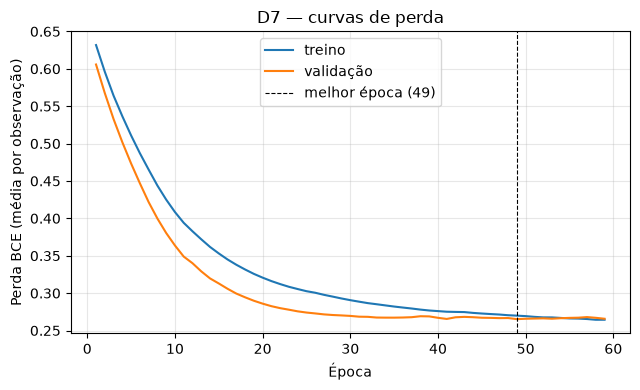

In [10]:
def treinar_com_parada(modelo, loader_treino, loader_validacao,
                       max_epocas=100, paciencia=10, min_delta=0.0001):
    """D7: treina, avalia a validação sem gradientes, guarda cópia independente do melhor
    estado, para por paciência e restaura os melhores pesos. Não recebe o loader de teste."""
    criterio = nn.BCEWithLogitsLoss()
    otim = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    hist = {'treino': [], 'validacao': []}
    melhor_perda, melhor_epoca, sem_melhora = float('inf'), 0, 0
    melhor_estado, motivo, epocas_feitas = None, 'max_epocas', 0
    for ep in range(1, max_epocas + 1):
        hist['treino'].append(treinar_epoca(modelo, loader_treino, otim, criterio, DISPOSITIVO))
        pv = avaliar_perda(modelo, loader_validacao, criterio, DISPOSITIVO)
        hist['validacao'].append(pv)
        epocas_feitas = ep
        if pv < melhor_perda - min_delta:
            melhor_perda, melhor_epoca, sem_melhora = pv, ep, 0
            melhor_estado = copy.deepcopy(modelo.state_dict())      # cópia independente
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                motivo = 'paciencia'
                break
    modelo.load_state_dict(melhor_estado)                           # restaura o melhor
    return {'historico': hist, 'melhor_epoca': melhor_epoca, 'epoca_final': epocas_feitas,
            'melhor_perda': melhor_perda, 'motivo': motivo}

fixar_semente(SEED)
modelo_final = criar_modelo(11, batchnorm=False).to(DISPOSITIVO)    # rede nova (11 -> 16 -> 1)
res_d7 = treinar_com_parada(modelo_final, loader_treino, loader_validacao,
                            max_epocas=100, paciencia=10, min_delta=0.0001)
historico = res_d7['historico']
print('Motivo da parada:', res_d7['motivo'], '| épocas executadas:', res_d7['epoca_final'])
print('Melhor época:', res_d7['melhor_epoca'], '| melhor perda de validação: %.5f' % res_d7['melhor_perda'])
perda_restaurada = avaliar_perda(modelo_final, loader_validacao, nn.BCEWithLogitsLoss(), DISPOSITIVO)
print('Perda de validação após restaurar: %.5f (igual à melhor? %s)' %
      (perda_restaurada, abs(perda_restaurada - res_d7['melhor_perda']) < 1e-6))
print('Perda de validação na última época treinada: %.5f' % historico['validacao'][-1])

fig, ax = plt.subplots(figsize=(6.5, 4))
ep = np.arange(1, len(historico['treino']) + 1)
ax.plot(ep, historico['treino'], label='treino'); ax.plot(ep, historico['validacao'], label='validação')
ax.axvline(res_d7['melhor_epoca'], color='k', ls='--', lw=.8, label=f"melhor época ({res_d7['melhor_epoca']})")
ax.set_xlabel('Época'); ax.set_ylabel('Perda BCE (média por observação)')
ax.set_title('D7 — curvas de perda'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(RESULTADOS/'d7_curvas_perda.png', dpi=130); plt.show()
pd.DataFrame({'epoca': ep, 'perda_treino': historico['treino'], 'perda_validacao': historico['validacao']}
             ).to_csv(RESULTADOS/'d7_historico.csv', index=False)

## D4. Custos como hipóteses explícitas
Descreva a ação de selecionar uma amostra como alta nota. Defina custos positivos de falso positivo e falso negativo, uma unidade e uma justificativa. Não existem custos reais no CSV. Acertos custam zero na simplificação deste laboratório.

**Decisão modelada.** O sistema prevê *positivo* → a amostra é encaminhada para a análise especial (como "alta nota", `quality >= 7`); prevê *negativo* → não é encaminhada.

* **Falso positivo (FP):** encaminhar uma amostra com nota < 7 → a análise especial é gasta em vão.
* **Falso negativo (FN):** deixar de encaminhar uma amostra com nota ≥ 7 → perde-se uma amostra de interesse.

**Custos — HIPÓTESES do exercício (a base não traz custos reais), em "unidades de esforço":** `C_FP = 1` e `C_FN = 3`. Justificativa: a classe de interesse é a minoritária (~14%), cada exemplar que escapa é dificilmente recuperado depois, enquanto uma análise a mais custa apenas uma unidade de esforço; por isso assume-se perder uma amostra boa como 3× pior que analisar uma ruim. Acertos custam 0. A razão `C_FP/(C_FP+C_FN) = 0,25` é o limiar teórico para probabilidades calibradas.

In [11]:
C_FP = 1.0   # hipótese: 1 unidade de esforço por análise especial desperdiçada
C_FN = 3.0   # hipótese: 3 unidades de esforço por amostra de alta nota perdida
print('C_FP =', C_FP, '| C_FN =', C_FN, '(unidades hipotéticas de esforço; acertos = 0)')

C_FP = 1.0 | C_FN = 3.0 (unidades hipotéticas de esforço; acertos = 0)


## D5 e D6. Escolha na validação e fórmula
Use `obter_escores(modelo_final, loader_validacao, DISPOSITIVO)` após a restauração. Compare limiares usando os rótulos da validação. Inclua os casos extremos; registre regra de empate ou resolução de uma grade. Compare com 0,5 e com `C_FP/(C_FP+C_FN)`. Investigue calibração sem transformar sigmoide em garantia de probabilidade.

Salve modelo, normalização, lista de entradas, custos e limiar como escolhas fixadas antes da próxima seção.

Candidatos avaliados: 273 (escores únicos + extremo "tudo negativo")
Limiar escolhido (validação): 0.2766 | empates de custo mínimo: 1
  custo total 60.0 (FP=33, FN=9) | custo médio 0.1887/obs
Limiar 0,5 (mesma validação): custo total 87.0 (FP=12, FN=25) | custo médio 0.2736/obs
Redução de custo na validação: 27.0 (31.0%)
Custo de "tudo negativo": 99.0 | "tudo positivo": 285.0

Limiar da fórmula C_FP/(C_FP+C_FN) = 0.250 -> custo total 62.0 (FP=35, FN=9)
Brier score (validação): 0.0790 | Brier do preditor "prevalência": 0.0930


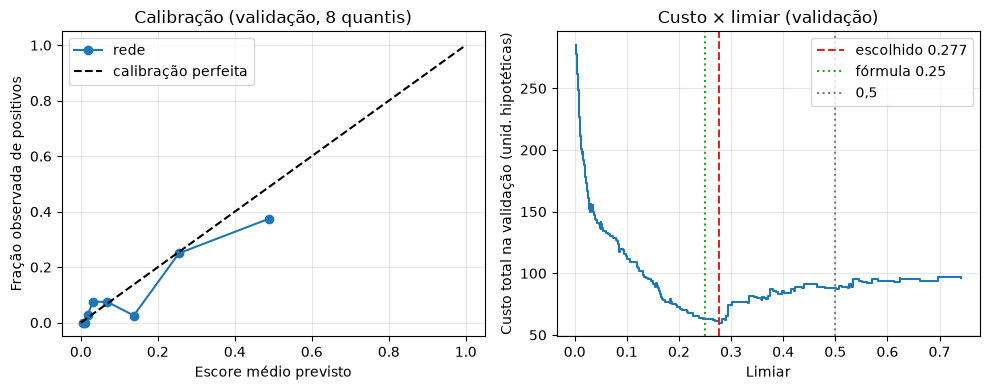


Decisão congelada: {'limiar': 0.27660998702049255, 'C_FP': 1.0, 'C_FN': 3.0, 'media': '...', 'desvio': '...', 'features': ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol'], 'melhor_epoca': 49}


In [12]:
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, roc_auc_score, auc,
                             precision_recall_curve, roc_curve, average_precision_score, brier_score_loss)
from sklearn.calibration import calibration_curve

def custo_total(y, escores, limiar, c_fp=None, c_fn=None):
    c_fp = C_FP if c_fp is None else c_fp
    c_fn = C_FN if c_fn is None else c_fn
    pred = (escores >= limiar).astype(int)
    fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    return c_fp * fp + c_fn * fn, fp, fn

y_val, s_val = obter_escores(modelo_final, loader_validacao, DISPOSITIVO)
# candidatos: todos os escores únicos (prevê tudo positivo a partir do menor) + um limiar > máx (tudo negativo)
candidatos = np.concatenate([np.unique(s_val), [np.inf]])
custos = np.array([custo_total(y_val, s_val, t)[0] for t in candidatos])
# desempate declarado: entre custos iguais, o MAIOR limiar (menos positivos previstos)
melhores = candidatos[custos == custos.min()]
limiar_escolhido = float(melhores.max())
c_esc, fp_e, fn_e = custo_total(y_val, s_val, limiar_escolhido)
c_05, fp_5, fn_5 = custo_total(y_val, s_val, 0.5)
n_val = len(y_val)
print(f'Candidatos avaliados: {len(candidatos)} (escores únicos + extremo "tudo negativo")')
print(f'Limiar escolhido (validação): {limiar_escolhido:.4f} | empates de custo mínimo: {len(melhores)}')
print(f'  custo total {c_esc:.1f} (FP={fp_e}, FN={fn_e}) | custo médio {c_esc/n_val:.4f}/obs')
print(f'Limiar 0,5 (mesma validação): custo total {c_05:.1f} (FP={fp_5}, FN={fn_5}) | custo médio {c_05/n_val:.4f}/obs')
print(f'Redução de custo na validação: {c_05 - c_esc:.1f} ({100*(c_05-c_esc)/c_05:.1f}%)' if c_05 > 0 else '')
print('Custo de "tudo negativo":', custos[-1], '| "tudo positivo":', custo_total(y_val, s_val, 0.0)[0])

# ---- D6: fórmula e calibração ----
t_formula = C_FP / (C_FP + C_FN)
c_form, fp_f, fn_f = custo_total(y_val, s_val, t_formula)
print(f'\nLimiar da fórmula C_FP/(C_FP+C_FN) = {t_formula:.3f} -> custo total {c_form:.1f} (FP={fp_f}, FN={fn_f})')
print(f'Brier score (validação): {brier_score_loss(y_val, s_val):.4f} | Brier do preditor "prevalência": {brier_score_loss(y_val, np.full(n_val, y_val.mean())):.4f}')
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
fr, mp = calibration_curve(y_val, s_val, n_bins=8, strategy='quantile')
ax[0].plot(mp, fr, 'o-', label='rede'); ax[0].plot([0, 1], [0, 1], 'k--', label='calibração perfeita')
ax[0].set_xlabel('Escore médio previsto'); ax[0].set_ylabel('Fração observada de positivos')
ax[0].set_title('Calibração (validação, 8 quantis)'); ax[0].legend(); ax[0].grid(alpha=.3)
cand_f = candidatos[np.isfinite(candidatos)]
ax[1].plot(cand_f, custos[:-1], drawstyle='steps-post')
ax[1].axvline(limiar_escolhido, color='C3', ls='--', label=f'escolhido {limiar_escolhido:.3f}')
ax[1].axvline(t_formula, color='C2', ls=':', label=f'fórmula {t_formula:.2f}')
ax[1].axvline(0.5, color='gray', ls=':', label='0,5')
ax[1].set_xlabel('Limiar'); ax[1].set_ylabel('Custo total na validação (unid. hipotéticas)')
ax[1].set_title('Custo × limiar (validação)'); ax[1].legend(); ax[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(RESULTADOS/'d5_d6_validacao.png', dpi=130); plt.show()

# ---- congela a decisão ----
decisao = {'limiar': limiar_escolhido, 'C_FP': C_FP, 'C_FN': C_FN, 'media': ds_treino.media.copy(),
           'desvio': ds_treino.desvio.copy(), 'features': list(FEATURES), 'melhor_epoca': res_d7['melhor_epoca']}
estado_congelado = copy.deepcopy(modelo_final.state_dict())
decisao_congelada = True
print('\nDecisão congelada:', {k: (v if not isinstance(v, np.ndarray) else '...') for k, v in decisao.items()})

## D1, D2 e D3. Avaliação final
Só agora obtenha escores no teste com o modelo restaurado e decisão congelada. Avalie as duas regras já fixadas (0,5 e limiar escolhido). O baseline usa a classe majoritária **do treino**. Produza matriz com ordem `[0, 1]`, métricas, prevalência e custos.

AUC-ROC e AUC-PR usam escores. Com `precision_recall_curve`, calcule a área trapezoidal usando `auc(recall, precision)`; se reportar `average_precision_score`, chame-a AP. Na ROC, desenhe a diagonal aleatória. Na PR, desenhe a prevalência do teste.

Não use o resultado do teste para voltar à busca. Relate os limites observados.

Teste: 320 obs | proporção positiva 0.1406 | classe majoritária do treino: 0
                       Regra  Limiar  TN  FP  FN  TP  Acurácia  Precisão  Revocação    F1  Custo/obs  AUC-ROC  AUC-PR     AP
           Trivial do treino     n/a 275   0  45   0    0.8594    0.0000     0.0000 0.000     0.4219   0.5000     NaN    NaN
                Rede: padrão     0.5 269   6  33  12    0.8781    0.6667     0.2667 0.381     0.3281   0.8906  0.5641 0.5736
Rede: escolhido na validação  0.2766 246  29  17  28    0.8562    0.4912     0.6222 0.549     0.2500   0.8906  0.5641 0.5736

Matriz de confusão — limiar 0,5 (linhas = real [0,1]; colunas = previsto [0,1])
        prev 0  prev 1
real 0     269       6
real 1      33      12

Matriz de confusão — limiar escolhido (0.2766) (linhas = real [0,1]; colunas = previsto [0,1])
        prev 0  prev 1
real 0     246      29
real 1      17      28


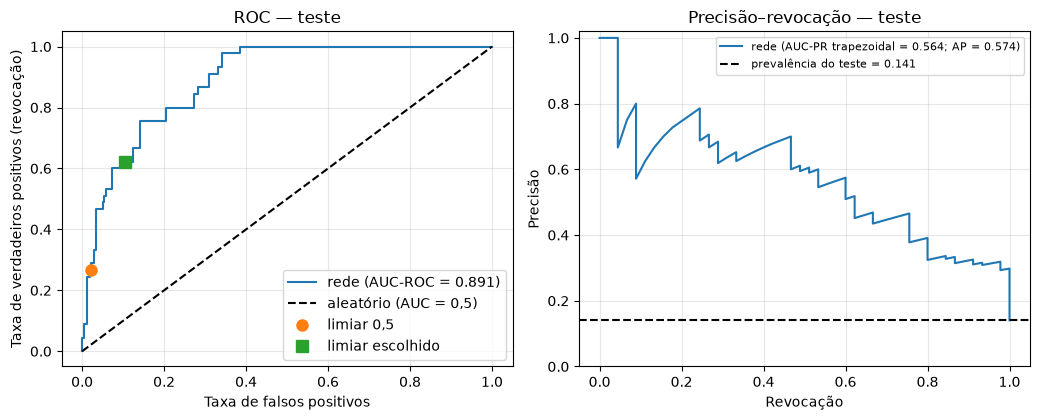

In [13]:
assert decisao_congelada and limiar_escolhido == decisao['limiar']
assert all(torch.equal(modelo_final.state_dict()[k], estado_congelado[k]) for k in estado_congelado)
y_te, s_te = obter_escores(modelo_final, loader_teste, DISPOSITIVO)        # escores do teste: uma vez
prev_te = y_te.mean()
classe_maj = int(particoes['treino'].alvo.mean() >= 0.5)                   # majoritária identificada no TREINO
print(f'Teste: {len(y_te)} obs | proporção positiva {prev_te:.4f} | classe majoritária do treino: {classe_maj}')

def metricas(y, pred, escores=None, nome='', limiar='-'):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    d = {'Regra': nome, 'Limiar': limiar, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
         'Acurácia': accuracy_score(y, pred),
         'Precisão': precision_score(y, pred, zero_division=0),     # convenção: 0 se nenhuma previsão positiva
         'Revocação': recall_score(y, pred, zero_division=0),
         'F1': f1_score(y, pred, zero_division=0),
         'Custo/obs': (C_FP * fp + C_FN * fn) / len(y)}
    if escores is not None:
        rec_prec = precision_recall_curve(y, escores)
        d['AUC-ROC'] = roc_auc_score(y, escores)
        d['AUC-PR'] = auc(rec_prec[1], rec_prec[0])               # área trapezoidal
        d['AP'] = average_precision_score(y, escores)
    return d

linhas = []
# baseline: escore constante = classe majoritária (0): ROC-AUC = 0,5 por empate total; áreas PR não reportadas
pred_triv = np.full(len(y_te), classe_maj)
d_triv = metricas(y_te, pred_triv, None, 'Trivial do treino', 'n/a')
d_triv['AUC-ROC'] = roc_auc_score(y_te, np.full(len(y_te), float(classe_maj)))
d_triv['AUC-PR'] = np.nan; d_triv['AP'] = np.nan
linhas.append(d_triv)
linhas.append(metricas(y_te, (s_te >= 0.5).astype(int), s_te, 'Rede: padrão', 0.5))
linhas.append(metricas(y_te, (s_te >= limiar_escolhido).astype(int), s_te, 'Rede: escolhido na validação', round(limiar_escolhido, 4)))
avaliacao_final = pd.DataFrame(linhas)
pd.set_option('display.width', 200)
print(avaliacao_final.round(4).to_string(index=False))
avaliacao_final.to_csv(RESULTADOS/'d_avaliacao_final.csv', index=False)

for nome, thr in [('limiar 0,5', 0.5), (f'limiar escolhido ({limiar_escolhido:.4f})', limiar_escolhido)]:
    cm = confusion_matrix(y_te, (s_te >= thr).astype(int), labels=[0, 1])
    print(f'\nMatriz de confusão — {nome} (linhas = real [0,1]; colunas = previsto [0,1])')
    print(pd.DataFrame(cm, index=['real 0', 'real 1'], columns=['prev 0', 'prev 1']).to_string())

# ---- D3: curvas ----
fpr, tpr, _ = roc_curve(y_te, s_te)
prec, rec, _ = precision_recall_curve(y_te, s_te)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.3))
ax[0].plot(fpr, tpr, label=f'rede (AUC-ROC = {roc_auc_score(y_te, s_te):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='aleatório (AUC = 0,5)')
for nome, thr, mk in [('0,5', 0.5, 'o'), ('escolhido', limiar_escolhido, 's')]:
    p = (s_te >= thr)
    ax[0].plot(((p) & (y_te == 0)).sum()/(y_te == 0).sum(), ((p) & (y_te == 1)).sum()/(y_te == 1).sum(), mk, ms=8, label=f'limiar {nome}')
ax[0].set_xlabel('Taxa de falsos positivos'); ax[0].set_ylabel('Taxa de verdadeiros positivos (revocação)')
ax[0].set_title('ROC — teste'); ax[0].legend(loc='lower right'); ax[0].grid(alpha=.3)
ax[1].plot(rec, prec, label=f'rede (AUC-PR trapezoidal = {auc(rec, prec):.3f}; AP = {average_precision_score(y_te, s_te):.3f})')
ax[1].axhline(prev_te, color='k', ls='--', label=f'prevalência do teste = {prev_te:.3f}')
ax[1].set_xlabel('Revocação'); ax[1].set_ylabel('Precisão'); ax[1].set_ylim(0, 1.02)
ax[1].set_title('Precisão–revocação — teste'); ax[1].legend(loc='upper right', fontsize=8); ax[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(RESULTADOS/'d3_curvas_roc_pr.png', dpi=130); plt.show()

## D8. Recomendação final
Escreva no README o parágrafo para quem decide: ação, limiar, evidência final, custos hipotéticos, riscos e limitações. Cite o conjunto avaliado. Não reivindique desempenho em novos produtores, regiões ou datas não observados.

## Conferência da entrega
Reinicie o kernel e execute tudo. O notebook preenchido deve mostrar as saídas de todas as partes; pendências não são resultados. Preencha o README e o arquivo obrigatório de uso de IA. Inclua as referências e registre alterações no apoio.

In [14]:
pendencias = []
for nome, valor in [('particoes', particoes), ('ds_treino', ds_treino),
    ('loader_treino', loader_treino), ('historico', historico),
    ('limiar_escolhido', limiar_escolhido), ('avaliacao_final', avaliacao_final)]:
    if valor is None:
        pendencias.append(nome)
if not tempos: pendencias.append('tempos A3')
if len(resultados_c) < 2: pendencias.append('dois resultados C')
print('Pendências estruturais:', pendencias)
print('Esta checagem não corrige a análise nem substitui o checklist do enunciado.')

Pendências estruturais: []
Esta checagem não corrige a análise nem substitui o checklist do enunciado.
